In [22]:
import random
import sys
import urllib.request
from pathlib import Path
import math

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn

In [2]:
SEED = 1337
torch.manual_seed(SEED)

try:
    ROOT = Path(__file__).resolve().parent
except NameError:  # exécution dans une cellule Jupyter : `__file__` n'existe pas
    ROOT = Path.cwd()

## 1. Le problème

Un lot de `B` séquences de `T` tokens, chacun représenté par un vecteur de
`C` canaux (son embedding). Jusqu'ici, chaque position était traitée
**seule** : le bigramme ne regarde que le token courant. On veut que chaque
position puisse **récupérer de l'information** des positions précédentes.

Une contrainte : le token 5 peut regarder les tokens 1 à 5, **jamais** 6 et
au-delà. À la génération, le futur n'existe pas encore ; s'il le voyait à
l'entraînement, le modèle apprendrait à tricher.

In [ ]:
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)
print(f"x : {tuple(x.shape)}   (batch, time, chennels)")

x : (4, 8, 2)   (batch, temps, canaux)


## 2. v1 : la moyenne du passé, avec des boucles

La communication la plus simple : chaque position prend la **moyenne** de
tous les vecteurs jusqu'à elle-même (« bag of words », `xbow`). C'est très
pauvre (l'ordre est perdu, tout le passé pèse autant), mais c'est un point
de départ.

In [7]:
x_demo = torch.tensor([[1., 0.],
                       [3., 2.],
                       [2., 4.],
                       [6., 2.]])  # 4 positions, 2 canaux

xbow_demo = torch.zeros_like(x_demo)
for t in range(4):
    xbow_demo[t] = x_demo[: t + 1].mean(dim=0)

print(xbow_demo)
# [[1., 0.],    ← (1)/1,        (0)/1
#  [2., 1.],    ← (1+3)/2,      (0+2)/2
#  [2., 2.],    ← (1+3+2)/3,    (0+2+4)/3
#  [3., 2.]]    ← (1+3+2+6)/4,  (0+2+4+2)/4

tensor([[1., 0.],
        [2., 1.],
        [2., 2.],
        [3., 2.]])


In [8]:
xbow = torch.zeros(B, T, C)
for b in range(B):
    for t in range(T):
        xprev = x[b, : t + 1]  # (t+1, C)
        xbow[b, t] = xprev.mean(dim=0)

print(x[0])
print(xbow[0])


tensor([[ 0.1808, -0.0700],
        [-0.3596, -0.9152],
        [ 0.6258,  0.0255],
        [ 0.9545,  0.0643],
        [ 0.3612,  1.1679],
        [-1.3499, -0.5102],
        [ 0.2360, -0.2398],
        [-0.9211,  1.5433]])
tensor([[ 0.1808, -0.0700],
        [-0.0894, -0.4926],
        [ 0.1490, -0.3199],
        [ 0.3504, -0.2238],
        [ 0.3525,  0.0545],
        [ 0.0688, -0.0396],
        [ 0.0927, -0.0682],
        [-0.0341,  0.1332]])


La première ligne est inchangée (moyenne d'un seul vecteur), la deuxième est
la moyenne des deux premières, etc. Deux boucles Python imbriquées : lent.

## 3. v2 : un produit matriciel

**L'astuce mathématique**. Multiplier par une matrice
triangulaire inférieure dont chaque ligne somme à 1 calcule exactement ces
moyennes. La ligne `t` de `wei` dit **avec quel poids** chaque position
passée contribue à la position `t`.

In [9]:
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(dim=1, keepdim=True)
print(wei)

xbow2 = wei @ x  # (T, T) @ (B, T, C) → (B, T, C) par broadcasting
print(f"v2 == v1 : {torch.allclose(xbow, xbow2, atol=1e-6)}")

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])
v2 == v1 : True


Le produit matriciel fait **toutes les positions en même temps**, là où le
RNN devait avancer pas à pas. C'est ce parallélisme qui a permis
d'entraîner des modèles de langue gigantesques sur GPU.

# 4. v3 : un softmax masqué

Troisième écriture, qui sera la bonne. On part de scores tous nuls, on met
**−∞** sur le futur, et on applique un softmax ligne par ligne : `exp(−∞) =
0`, et les scores nuls deviennent des poids égaux. Même résultat.

Pourquoi ce détour ? Parce que maintenant les scores peuvent être
**n'importe quoi** : il suffira de les calculer à partir des données, et le
softmax en fera toujours des poids positifs qui somment à 1, sans jamais
regarder le futur.

In [10]:
tril = torch.tril(torch.ones(T, T))
wei = torch.zeros(T, T)
wei = wei.masked_fill(tril == 0, float("-inf"))
print(wei)
wei = F.softmax(wei, dim=-1)
xbow3 = wei @ x
print(f"v3 == v1 : {torch.allclose(xbow, xbow3, atol=1e-6)}")

tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., -inf, -inf, -inf, -inf],
        [0., 0., 0., 0., 0., -inf, -inf, -inf],
        [0., 0., 0., 0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0., 0., 0., 0.]])
v3 == v1 : True


## 5. v4 : query, key, value

Tous les tokens passés ne se valent pas. Une voyelle cherche peut-être la
consonne qui la précède ; un pronom cherche le nom auquel il renvoie. On veut
des poids **qui dépendent du contenu**.

Chaque token émet trois vecteurs, par trois couches linéaires :

- une **query** `q` : « voilà ce que je cherche » ;
- une **key** `k` : « voilà ce que je contiens » ;
- une **value** `v` : « voilà ce que je transmets si on me choisit ».

Le score entre la position `i` et la position `j` est le produit scalaire
`q_i · k_j` : grand si ce que `i` cherche ressemble à ce que `j` contient.
C'est la similarité du script 03, sans la normalisation. Puis masque,
softmax, et moyenne pondérée des **values**.

out : (4, 8, 16)
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1574, 0.8426, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2088, 0.1646, 0.6266, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5792, 0.1187, 0.1889, 0.1131, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0294, 0.1052, 0.0469, 0.0276, 0.7909, 0.0000, 0.0000, 0.0000],
        [0.0176, 0.2689, 0.0215, 0.0089, 0.6812, 0.0019, 0.0000, 0.0000],
        [0.1691, 0.4066, 0.0438, 0.0416, 0.1048, 0.2012, 0.0329, 0.0000],
        [0.0210, 0.0843, 0.0555, 0.2297, 0.0573, 0.0709, 0.2423, 0.2391]])


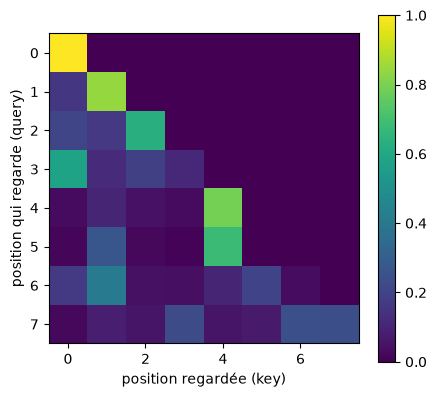

In [11]:
torch.manual_seed(SEED)
B, T, C = 4, 8, 32
x = torch.randn(B, T, C)

head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)

k = key(x)  # (B, T, 16)
q = query(x)  # (B, T, 16)
wei = q @ k.transpose(-2, -1)  # (B, T, 16) @ (B, 16, T) → (B, T, T)

tril = torch.tril(torch.ones(T, T))
wei = wei.masked_fill(tril == 0, float("-inf"))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v  # (B, T, T) @ (B, T, 16) → (B, T, 16)
print(f"out : {tuple(out.shape)}")
print(wei[0].detach())

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(wei[0].detach(), cmap="viridis")
ax.set_xlabel("position regardée (key)")
ax.set_ylabel("position qui regarde (query)")
fig.colorbar(im, ax=ax)


Les poids ne sont plus uniformes : chaque ligne répartit son attention
différemment, selon le contenu. Ici les couches sont aléatoires ;
l'entraînement apprendra quoi chercher.

**Lecture « communication ».**
l'attention est un mécanisme de communication dans un graphe orienté. Chaque
nœud (token) agrège une somme pondérée des messages (values) des nœuds qui
pointent vers lui. Le masque décide du graphe : ici, chaque token reçoit de
lui-même et de tous ceux qui le précèdent.

Il n'y a **aucune communication entre les séquences d'un lot** : le produit
matriciel est fait séquence par séquence (`(B, T, T)`).

## 6. Le facteur 1/√d

À la section 5, on a passé les scores `q @ kᵀ` directement au softmax. Il
manque une étape : la vraie attention les **divise par `√head_size`** avant
le softmax, et c'est ce que feront toutes les versions suivantes. Pourquoi ?

**Les scores sont grands.** Un score est un produit scalaire, une somme de
`head_size` produits :

     q · k = q₁k₁ + q₂k₂ + … + q₁₆k₁₆

 Si les composantes de `q` et `k` sont de variance 1, chaque produit aussi ;
 et une somme de 16 termes indépendants a une variance d'environ **16**, soit
 un écart-type de 4. Les scores sortent entre −8 et +8 au lieu de −2 et +2.
 Plus la tête est large, pire c'est : avec 128 dimensions, l'écart-type
 monte à 11.

In [13]:
k = torch.randn(B, T, head_size)
q = torch.randn(B, T, head_size)
scores = q @ k.transpose(-2, -1)
scaled = scores * head_size**-0.5
print(f"variance des scores bruts         : {scores.var().item():.2f}")
print(f"variance après / √{head_size} (= / {head_size**0.5:.0f}) : {scaled.var().item():.2f}")

variance des scores bruts         : 15.93
variance après / √16 (= / 4) : 1.00


**Des scores grands rendent le softmax pointu.** Le softmax amplifie les
écarts entre scores : plus ils sont grands, plus le plus élevé écrase les
autres. Les poids peuvent être **répartis** (tous les tokens reçoivent une part comparable) ou **pointus** (presque tout le poids va à un seul token,
comme un one-hot). Regardons la dernière position du premier exemple, qui
voit les 8 tokens (pas besoin de masque) :

In [14]:
row, row_scaled = scores[0, -1], scaled[0, -1]
torch.set_printoptions(precision=2, sci_mode=False)
print(f"softmax(scores bruts) : {F.softmax(row, dim=-1)}")
print(f"softmax(scores / √{head_size}) : {F.softmax(row_scaled, dim=-1)}")
torch.set_printoptions(profile="default")

softmax(scores bruts) : tensor([0.00, 0.00, 0.01, 0.00, 0.98, 0.00, 0.00, 0.00])
softmax(scores / √16) : tensor([0.07, 0.03, 0.14, 0.11, 0.44, 0.09, 0.06, 0.05])


Sans la division, la position donne presque toute son attention à un token,
choisi **par le hasard de l'initialisation** : `q` et `k` n'ont encore rien
appris. Avec la division, l'attention part d'un mélange, et c'est
l'entraînement qui décidera où la concentrer.

**Un softmax pointu ne laisse plus passer le gradient.** Pour apprendre, le
modèle doit pouvoir se dire : « si j'augmente un peu le score de ce token,
son poids augmente un peu ». Quand un poids vaut déjà 0,99 et les autres
presque 0, bouger un peu les scores ne change presque rien aux poids : le
softmax est dans sa zone plate, comme un `tanh` saturé (script 03). On le
mesure : la sensibilité des poids aux scores, c'est-à-dire le gradient du
softmax, moyenné sur toutes les positions.

In [20]:
def softmax_sensitivity(rows: torch.Tensor) -> float:
    """Taille moyenne du gradient des poids du softmax par rapport aux scores.

    Args:
        rows: Scores, une ligne par position, de forme `(N, T)`.

    Returns:
        La norme moyenne de la jacobienne de `softmax` sur les N lignes.
    """
    norms = [torch.autograd.functional.jacobian(lambda s: F.softmax(s, dim=-1), r).norm() for r in rows]
    return torch.stack(norms).mean().item()


print(f"{'head_size':>9} {'poids max, brut':>16} {'poids max, / √d':>16} {'gradient, brut':>15} {'gradient, / √d':>15}")
for d in [16, 64, 256]:
    q_d, k_d = torch.randn(B, T, d), torch.randn(B, T, d)
    raw = (q_d @ k_d.transpose(-2, -1)).reshape(-1, T)
    fixed = raw * d**-0.5
    print(f"{d:>9} {F.softmax(raw, dim=-1).max(dim=-1).values.mean():>10.2f} "
          f"{F.softmax(fixed, dim=-1).max(dim=-1).values.mean():>16.2f} "
          f"{softmax_sensitivity(raw):>15.3f} {softmax_sensitivity(fixed):>10.3f}")

head_size  poids max, brut  poids max, / √d  gradient, brut  gradient, / √d
       16       0.79             0.37           0.219      0.361
       64       0.83             0.33           0.178      0.363
      256       0.90             0.34           0.135      0.373


Sans la division, plus la tête est large, plus le softmax est pointu (le
poids du token favori approche 1) et plus le gradient s'effondre : le
modèle ne peut plus réorienter son attention. Avec la division, les scores
gardent une variance de 1 quelle que soit la taille de la tête : le
softmax reste dans sa zone utile, et le gradient ne dépend plus de
`head_size`.

D'où le nom complet du mécanisme : **scaled dot-product attention**,
l'attention par produit scalaire **mis à l'échelle**.

## 7. L'attention ne connaît pas l'ordre

Rien dans le calcul ne dit **où** est un token : les scores ne dépendent que
des contenus. Sans masque, mélanger les tokens mélange simplement les
sorties de la même façon : pour l'attention, « le chat mange la souris » et
« la souris mange le chat » sont le même ensemble de vecteurs.


In [21]:
torch.manual_seed(SEED)
x1 = torch.randn(1, T, C)
perm = torch.randperm(T)


def attention_no_mask(x_: torch.Tensor) -> torch.Tensor:
    """Une tête d'attention sans masque, avec les couches définies plus haut."""
    q_, k_, v_ = query(x_), key(x_), value(x_)
    wei_ = F.softmax(q_ @ k_.transpose(-2, -1) * head_size**-0.5, dim=-1)
    return wei_ @ v_


out_then_perm = attention_no_mask(x1)[:, perm]
perm_then_out = attention_no_mask(x1[:, perm])
print(f"attention(permuté) == permuté(attention) : {torch.allclose(out_then_perm, perm_then_out, atol=1e-6)}")

attention(permuté) == permuté(attention) : True


On ajoute donc l'information de position **à l'embedding de chaque token**.
Deux solutions :

- **apprise** (le choix de GPT) : une seconde table
  d'embeddings, indexée par la position `0 … block_size - 1` ;
- **sinusoïdale** (le choix d'*Attention is All You Need*) : des sinus et
  cosinus de fréquences différentes, fixes, sans aucun paramètre.

positions apprises : (64, 32) paramètres


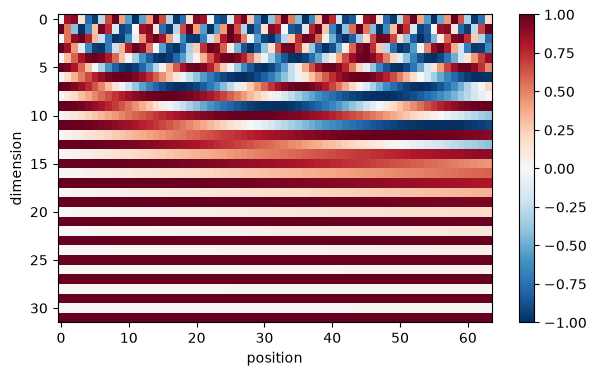

In [23]:
block_size, n_embd = 64, 32
position_embedding = nn.Embedding(block_size, n_embd)
print(f"positions apprises : {tuple(position_embedding.weight.shape)} paramètres")


def sinusoidal_encoding(block_size_: int, d_model: int) -> torch.Tensor:
    """Encodage positionnel d'*Attention is All You Need*.

    PE[pos, 2i] = sin(pos / 10000^(2i/d)), PE[pos, 2i+1] = cos(pos / 10000^(2i/d)).

    Args:
        block_size_: Nombre de positions.
        d_model: Dimension des embeddings (paire).

    Returns:
        Un tenseur `(block_size_, d_model)`.
    """
    pos = torch.arange(block_size_).unsqueeze(1)
    div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
    pe = torch.zeros(block_size_, d_model)
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe


pe = sinusoidal_encoding(block_size, n_embd)
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(pe.T, cmap="RdBu_r", aspect="auto")
ax.set_xlabel("position")
ax.set_ylabel("dimension")
fig.colorbar(im, ax=ax)

Chaque ligne est une dimension, chaque colonne une
position. Les premières dimensions oscillent vite (elles changent à chaque
position), les dernières très lentement. Comme les aiguilles d'une horloge :
aucune ne suffit seule, mais leur combinaison désigne une position unique.
Chaque colonne est la signature d'une position, ajoutée à l'embedding du
token.

**La fenêtre de contexte.** L'encodage appris est un tableau, comme les
embeddings de caractères du script 03 : une ligne par position, de 0 à
`block_size - 1`. Avec `block_size = 64`, si on donne au modèle un texte de
100 tokens, il cherche la ligne de la position 64, qui n'existe pas : c'est
**impossible**, comme demander à un dictionnaire une clé absente. C'est la
**fenêtre de contexte** : la longueur maximale de texte que le modèle peut
lire. L'encodage sinusoïdal, lui, est une formule qui répond pour n'importe
quelle position, donc il n'y a pas d'erreur ; mais le modèle n'a vu que les
positions 0 à 63 pendant l'entraînement, et il ne sait pas quoi faire des
suivantes. Dans les deux cas, un modèle ne lit bien que les longueurs vues à
l'entraînement : c'est pour ça qu'un LLM annonce une fenêtre de contexte
(par exemple 128 000 tokens).

## 8. Encodeur, décodeur, cross-attention

- **Bloc décodeur** (ce qu'on construit) : avec masque triangulaire. Chaque
  token ne voit que le passé. Sert à **générer** (GPT).
- **Bloc encodeur** : **sans** masque. Tous les tokens se voient. Sert à
  **comprendre** une phrase entière (BERT, classification, embeddings de
  phrases).
- **Self-attention** : queries, keys et values viennent de la même
   séquence. **Cross-attention** : les queries viennent d'une séquence, keys
   et values d'une autre. C'est le pont entre l'encodeur et le décodeur du
   Transformer de traduction du papier original, et la façon dont un texte
   conditionne une image en diffusion (jour 6).

## 9. Plusieurs têtes

Une seule tête ne peut chercher qu'**une chose à la fois**. On en fait
tourner plusieurs en parallèle, chacune avec ses propres query / key /
value, de taille `n_embd / n_head`, puis on concatène. Le coût est le même
qu'une grosse tête ; le modèle peut suivre plusieurs relations à la fois
(la lettre précédente, le début du mot, la ponctuation…).

In [27]:
class Head(nn.Module):
    """Une tête de self-attention masquée.

    Args:
        n_embd: Dimension des vecteurs en entrée.
        head_size: Dimension des query / key / value.
        block_size: Longueur maximale de séquence (taille du masque).
    """

    def __init__(self, n_embd: int, head_size: int, block_size: int) -> None:
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        # Le masque n'est pas un paramètre : un buffer suit le modèle sur le
        # device et dans le state_dict, sans recevoir de gradient.
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        _, T_, _ = x.shape
        k_, q_ = self.key(x), self.query(x)
        wei_ = q_ @ k_.transpose(-2, -1) * k_.shape[-1] ** -0.5
        wei_ = wei_.masked_fill(self.tril[:T_, :T_] == 0, float("-inf"))
        wei_ = F.softmax(wei_, dim=-1)
        return wei_ @ self.value(x)


class MultiHeadAttention(nn.Module):
    """Plusieurs têtes en parallèle, concaténées."""

    def __init__(self, n_embd: int, n_head: int, block_size: int) -> None:
        super().__init__()
        self.heads = nn.ModuleList(Head(n_embd, n_embd // n_head, block_size) for _ in range(n_head))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.cat([h(x) for h in self.heads], dim=-1)


mha = MultiHeadAttention(n_embd=32, n_head=4, block_size=8)
print(f"4 têtes de taille 8 : {tuple(mha(torch.randn(B, T, 32)).shape)}")

4 têtes de taille 8 : (4, 8, 32)
